# การทำนายการลาออกของพนักงาน (Employee Attrition Prediction)
**Dataset:** IBM HR Analytics Employee Attrition & Performance

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## ขั้นตอนที่ 1: การโหลดและสำรวจข้อมูลเบื้องต้น (Data Loading & EDA)

In [2]:
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
print(f"ขนาดข้อมูล: {df.shape[0]} แถว, {df.shape[1]} คอลัมน์")
print(f"Missing Values: {df.isnull().sum().sum()}")
df.head()


ขนาดข้อมูล: 1470 แถว, 35 คอลัมน์
Missing Values: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


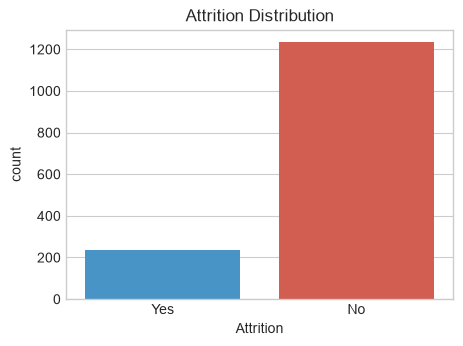

In [3]:
# สัดส่วนตัวแปรเป้าหมาย Attrition
plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x='Attrition', palette=['#3498db', '#e74c3c'], hue='Attrition', legend=False)
plt.title('Attrition Distribution')
plt.show()


## ขั้นตอนที่ 2: การเตรียมข้อมูล (Data Preprocessing & Feature Engineering)

In [4]:
# ตัดคอลัมน์ที่ไม่จำเป็น
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
df_cleaned = df.drop(columns=[col for col in drop_cols if col in df.columns])

# แปลง Target: Yes = 1, No = 0
df_cleaned['Attrition'] = df_cleaned['Attrition'].map({'Yes': 1, 'No': 0})

# One-Hot Encoding
categorical_cols = df_cleaned.select_dtypes(include=['object', 'string']).columns.tolist()
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['Attrition'])
y = df_encoded['Attrition']

print(f"X shape: {X.shape}, y shape: {y.shape}")


X shape: (1470, 44), y shape: (1470,)


## ขั้นตอนที่ 3: การแบ่งชุดข้อมูลและการปรับสเกล (Train-Test Split & Feature Scaling)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Train samples: 1176, Test samples: 294


## ขั้นตอนที่ 4: การสร้างและฝึกสอนโมเดล (Model Training)

In [6]:
models = {
    'Logistic Regression': (LogisticRegression(random_state=42, max_iter=1000), True),
    'Random Forest': (RandomForestClassifier(random_state=42, n_estimators=100), False),
    'Naive Bayes': (GaussianNB(), True),
    'SVM (RBF Kernel)': (SVC(random_state=42, probability=True), True)
}

results = []
conf_matrices = {}
y_preds = {}
y_probs = {}

for name, (model, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_preds[name] = y_pred

    if hasattr(model, 'predict_proba'):
        y_probs[name] = model.predict_proba(X_te)[:, 1]
    else:
        y_probs[name] = model.decision_function(X_te)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })
    conf_matrices[name] = confusion_matrix(y_test, y_pred)

results_df = pd.DataFrame(results)


## ขั้นตอนที่ 5: ตารางเปรียบเทียบค่าตัวชี้วัด (Model Comparison Table)

In [7]:
display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).highlight_max(color='#d4edda', axis=0))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384
1,Random Forest,0.8333,0.4167,0.1064,0.1695
2,Naive Bayes,0.6156,0.2500,0.7021,0.3687
3,SVM (RBF Kernel),0.8673,0.9000,0.1915,0.3158


## ขั้นตอนที่ 6: การแสดงผล Confusion Matrix

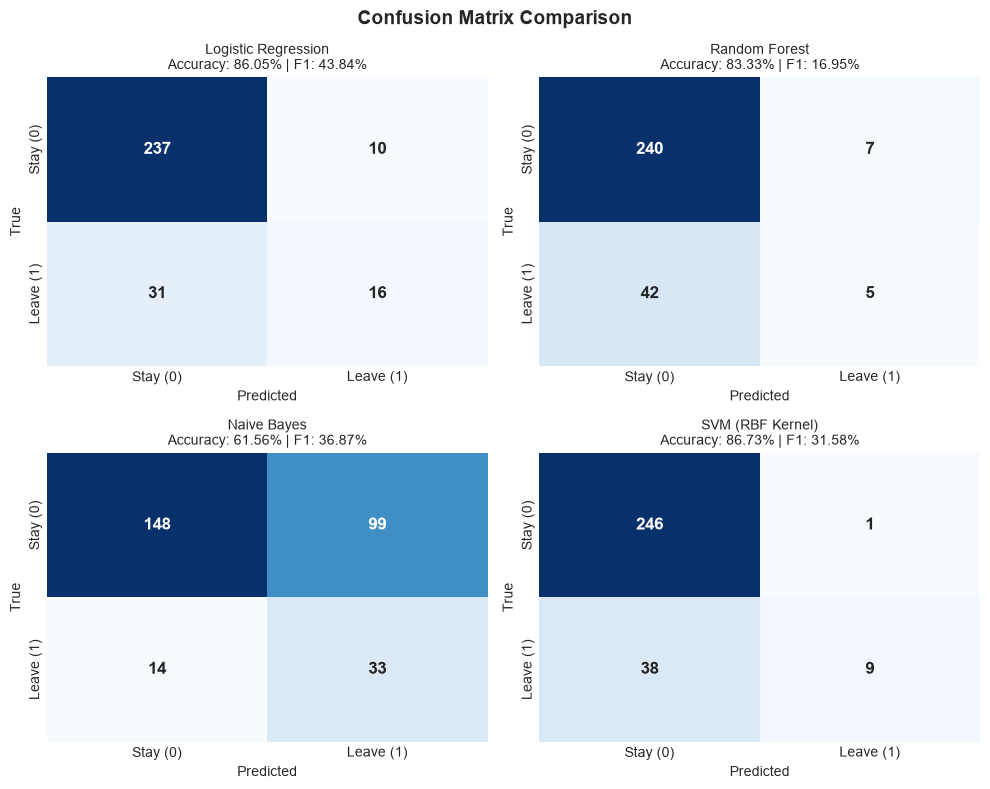

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
fig.suptitle('Confusion Matrix Comparison', fontsize=14, fontweight='bold')

for idx, (name, cm) in enumerate(conf_matrices.items()):
    ax = axes[idx // 2, idx % 2]
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        xticklabels=['Stay (0)', 'Leave (1)'],
        yticklabels=['Stay (0)', 'Leave (1)'],
        annot_kws={'size': 12, 'weight': 'bold'}
    )
    acc = results_df.loc[results_df['Model'] == name, 'Accuracy'].values[0]
    f1 = results_df.loc[results_df['Model'] == name, 'F1-Score'].values[0]
    ax.set_title(f"{name}\nAccuracy: {acc:.2%} | F1: {f1:.2%}", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()


## ขั้นตอนที่ 7: กราฟเปรียบเทียบตัวชี้วัดและกราฟ ROC-AUC Curves

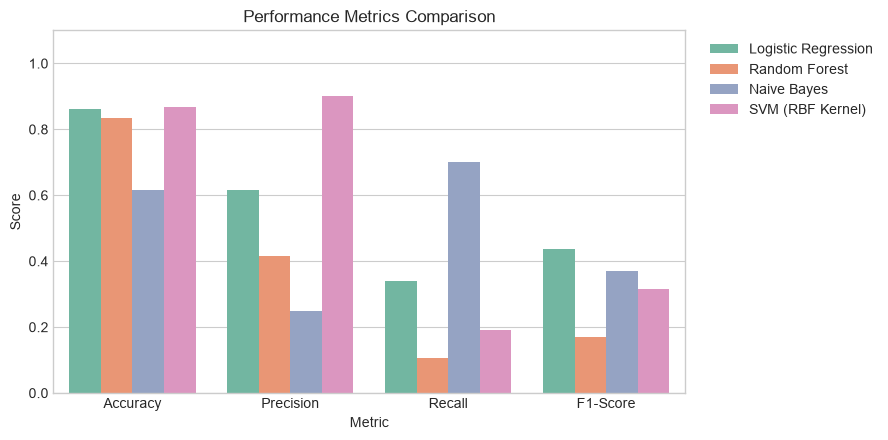

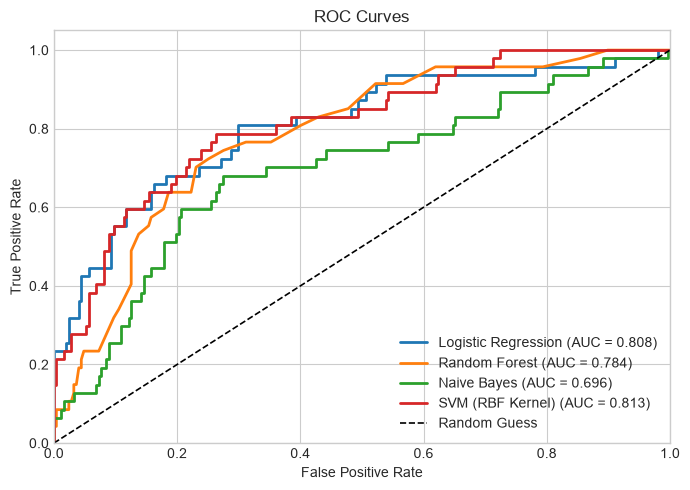

In [9]:
# 1. กราฟเปรียบเทียบตัวชี้วัด
df_melted = pd.melt(results_df, id_vars=['Model'], var_name='Metric', value_name='Score')
plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='Set2')
plt.title('Performance Metrics Comparison')
plt.ylim(0, 1.1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. กราฟ ROC Curves
plt.figure(figsize=(7, 5))
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probs[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## ขั้นตอนที่ 8: การวิเคราะห์ปัจจัยสำคัญที่มีผลต่อการลาออก (Feature Importance)

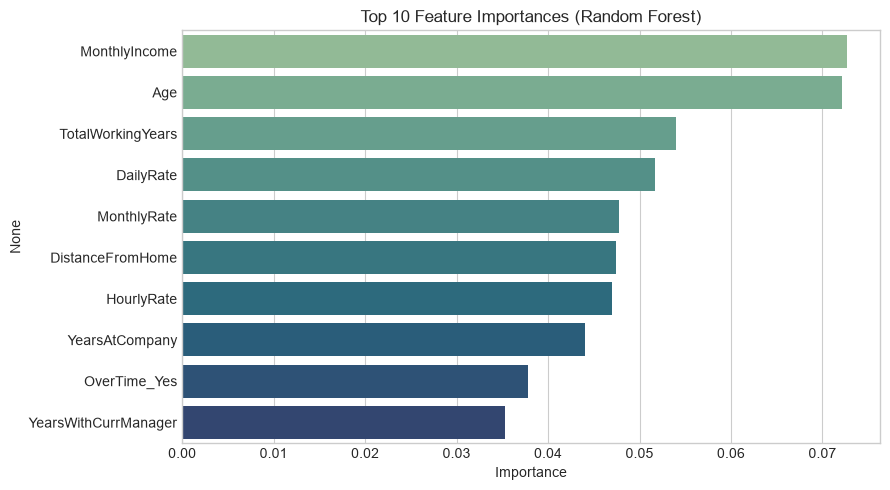

In [10]:
rf_model = models['Random Forest'][0]
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=feat_importances.head(10).values,
    y=feat_importances.head(10).index,
    palette='crest',
    hue=feat_importances.head(10).index,
    legend=False
)
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## ขั้นตอนที่ 9: สรุปผลการทดลอง (Summary)

In [11]:
# แสดงผลสรุปภาพรวมตัวชี้วัดทั้งหมด
summary_table = results_df.copy()
summary_table['Highest_Metric'] = ['Best F1-Score', 'High Accuracy', 'Best Recall', 'Best Precision']
display(summary_table)


,Model,Accuracy,Precision,Recall,F1-Score,Highest_Metric
0,Logistic Regression,0.860544,0.615385,0.340426,0.438356,Best F1-Score
1,Random Forest,0.833333,0.416667,0.106383,0.169492,High Accuracy
2,Naive Bayes,0.615646,0.250000,0.702128,0.368715,Best Recall
3,SVM (RBF Kernel),0.867347,0.900000,0.191489,0.315789,Best Precision
